# Click&Buy Latam — Análisis Exploratorio de Datos (EDA)

## Trabajo Práctico Integrador

**Materia:** Introducción al Análisis de Datos  
**Grupo:** 1  
**Caso:** E-Commerce y Retail  
**Rol:** Analista / Científico de Datos  
**Responsables:** Mariano Torres Mari y Santiago Juárez  

## Objetivo

Realizar un análisis descriptivo, exploratorio y diagnóstico
del dataset procesado por Ingeniería Analítica, aplicando
los conceptos desarrollados en la Unidad 4.

Se busca identificar patrones comerciales, analizar el
rendimiento por categoría, estudiar el ticket promedio
según canal de venta y método de pago, y evaluar el
impacto de las cancelaciones y devoluciones.

## 1. Importación de librerías

Se importan las herramientas necesarias para realizar
el análisis estadístico y la visualización de datos,
siguiendo los contenidos de la Unidad 4.

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

## 2. Carga del dataset limpio

Se utiliza el archivo procesado por Ingeniería Analítica,
ubicado en la carpeta data/processed.

No se modifica el dataset original ni se repiten los
procesos de limpieza realizados por las etapas anteriores.

In [82]:
# Identificar la carpeta raíz del proyecto
BASE = Path.cwd()

if BASE.name == "notebooks":
    BASE = BASE.parent

# Ruta del dataset limpio
SOURCE = BASE / "data" / "processed" / "dataset_limpio.csv"

# Cargar el dataset
df = pd.read_csv(SOURCE, encoding="utf-8-sig")

# Mostrar las primeras cinco filas
df.head()

,ID_Transaccion,Fecha,ID_Cliente,Categoria,Producto,Precio_Unitario,Cantidad,Descuento_Pct,Monto_Total_USD,Metodo_Pago,...,Descuento_Imputado,Diferencia_Monto_Calculado_USD,Monto_Consistente,Cantidad_Negativa,Outlier_IQR_Precio,Outlier_ZScore_Precio,Outlier_IQR_Cantidad,Outlier_ZScore_Cantidad,Outlier_IQR_Monto,Outlier_ZScore_Monto
0,TX-G1-10000,2025-11-24,CLI-395,Electrónica,"Smart TV 55""",423.41,1,0.00,423.41,Transferencia,...,True,0.0,True,False,False,False,False,False,False,False
1,TX-G1-10001,2025-02-27,CLI-568,Electrónica,Auriculares Bluetooth,616.21,1,0.20,492.97,Tarjeta Crédito,...,False,0.0,True,False,False,False,False,False,False,False
2,TX-G1-10002,2025-01-13,CLI-347,Hogar,Set de Sartenes,229.55,1,0.05,218.07,Transferencia,...,False,-0.0,True,False,False,False,False,False,False,False
3,TX-G1-10003,2025-05-21,CLI-187,Belleza,Secador de Pelo,33.94,1,0.20,27.15,Tarjeta Crédito,...,False,-0.0,True,False,False,False,False,False,False,False
4,TX-G1-10004,2025-05-06,CLI-144,Indumentaria,Pantalón Jean,58.69,1,0.00,58.69,MercadoPago,...,False,0.0,True,False,False,False,False,False,False,False


## 3. Validación inicial del dataset

Antes de comenzar el análisis estadístico, se comprueban
las dimensiones, los tipos de datos, los valores nulos
y la unicidad de las transacciones.

In [83]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
print("Valores nulos:", df.isna().sum().sum())
print("Transacciones duplicadas:", 
      df.duplicated(subset="ID_Transaccion").sum())

print("\nInformación del dataset:")
df.info()

Filas: 2000
Columnas: 23
Valores nulos: 0
Transacciones duplicadas: 0

Información del dataset:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ID_Transaccion                  2000 non-null   str    
 1   Fecha                           2000 non-null   str    
 2   ID_Cliente                      2000 non-null   str    
 3   Categoria                       2000 non-null   str    
 4   Producto                        2000 non-null   str    
 5   Precio_Unitario                 2000 non-null   float64
 6   Cantidad                        2000 non-null   int64  
 7   Descuento_Pct                   2000 non-null   float64
 8   Monto_Total_USD                 2000 non-null   float64
 9   Metodo_Pago                     2000 non-null   str    
 10  Canal_Venta                     2000 non-null   str    
 11  Estado_Ped

## 4. Identificación de los estados de pedido

Se analiza la distribución de los estados de pedido
para diferenciar las ventas entregadas, los pedidos
en tránsito, las cancelaciones y las devoluciones.

Esta clasificación permite evitar interpretaciones
incorrectas de los ingresos comerciales.

In [84]:
# Cantidad de transacciones por estado
estados = df["Estado_Pedido"].value_counts()

# Porcentaje de transacciones por estado
porcentajes = df["Estado_Pedido"].value_counts(
    normalize=True
) * 100

# Tabla de resumen
resumen_estados = pd.DataFrame({
    "Cantidad": estados,
    "Porcentaje": porcentajes.round(2)
})

resumen_estados

,Cantidad,Porcentaje
Estado_Pedido,,
Entregado,1640,82.0
En Tránsito,184,9.2
Cancelado,92,4.6
Devuelto,84,4.2


### 4.1. Análisis de cantidades negativas

Ingeniería Analítica conservó los registros con
cantidades negativas y los identificó mediante
una columna de control.

Se analiza su distribución por estado de pedido,
sin asumir que todas las cantidades negativas
representan devoluciones.

In [85]:
# Filtrar transacciones con cantidades negativas
negativos = df[df["Cantidad"] < 0]

print("Cantidad de registros negativos:", len(negativos))

# Cantidades negativas por estado
negativos["Estado_Pedido"].value_counts()

Cantidad de registros negativos: 26


Estado_Pedido
Entregado    23
Devuelto      2
Cancelado     1
Name: count, dtype: int64

In [86]:
negativos[[
    "ID_Transaccion",
    "Categoria",
    "Producto",
    "Cantidad",
    "Monto_Total_USD",
    "Estado_Pedido"
]]

,ID_Transaccion,Categoria,Producto,Cantidad,Monto_Total_USD,Estado_Pedido
124,TX-G1-10124,Belleza,Kit Maquillaje,-1,-31.39,Entregado
254,TX-G1-10254,Deportes,Colchoneta Yoga,-1,-165.01,Entregado
392,TX-G1-10392,Indumentaria,Buzo con Capucha,-1,-55.43,Entregado
415,TX-G1-10415,Belleza,Perfume Floral,-1,-45.12,Devuelto
422,TX-G1-10422,Hogar,Cafetera Express,-1,-231.68,Entregado
512,TX-G1-10512,Hogar,Batidora Planetaria,-1,-130.47,Entregado
533,TX-G1-10533,Electrónica,"Tablet 10""",-1,-456.94,Entregado
645,TX-G1-10645,Deportes,Colchoneta Yoga,-1,-120.26,Entregado
680,TX-G1-10680,Belleza,Kit Maquillaje,-1,-39.15,Entregado
769,TX-G1-10769,Electrónica,Smartphone Pro,-1,-423.65,Entregado


### 4.2. Análisis de montos por estado de pedido

Se agrupan las transacciones según su estado
para conocer la cantidad de operaciones, el monto
total registrado y el importe promedio.

Los montos registrados no representan necesariamente
ingresos efectivos de la empresa.

In [87]:
resumen_montos = df.groupby("Estado_Pedido").agg(
    Transacciones=("ID_Transaccion", "count"),
    Monto_Total_USD=("Monto_Total_USD", "sum"),
    Monto_Promedio_USD=("Monto_Total_USD", "mean")
)

resumen_montos.round(2)

,Transacciones,Monto_Total_USD,Monto_Promedio_USD
Estado_Pedido,,,
Cancelado,92,24433.55,265.58
Devuelto,84,23047.99,274.38
En Tránsito,184,48025.82,261.01
Entregado,1640,473761.33,288.88


### 4.3. Definición de criterios comerciales

Para el análisis del rendimiento comercial y del ticket
promedio se consideran los pedidos entregados con
cantidades e importes positivos.

Los pedidos cancelados, devueltos y en tránsito se
analizan por separado.

Los registros negativos se conservan en el dataset
original para su revisión, pero no se consideran
ventas positivas.

Este criterio permite estimar las ventas efectivas
sin confundirlas con operaciones pendientes o ajustes.

Los ingresos calculados en este análisis representan
el monto de las ventas positivas entregadas.

No equivalen necesariamente a ingresos netos contables,
debido a que no se dispone de información sobre
reembolsos confirmados, costos ni motivos de los
registros negativos.

In [88]:
# Seleccionar ventas entregadas con valores positivos
ventas = df[
    (df["Estado_Pedido"] == "Entregado") &
    (df["Cantidad"] > 0) &
    (df["Monto_Total_USD"] > 0)
].copy()

# Separar los demás estados
cancelados = df[df["Estado_Pedido"] == "Cancelado"].copy()
devueltos = df[df["Estado_Pedido"] == "Devuelto"].copy()
en_transito = df[df["Estado_Pedido"] == "En Tránsito"].copy()

print("Ventas positivas entregadas:", len(ventas))
print("Pedidos cancelados:", len(cancelados))
print("Pedidos devueltos:", len(devueltos))
print("Pedidos en tránsito:", len(en_transito))
print("Registros negativos:", len(negativos))

Ventas positivas entregadas: 1617
Pedidos cancelados: 92
Pedidos devueltos: 84
Pedidos en tránsito: 184
Registros negativos: 26


## 5. Análisis descriptivo y univariado

El análisis univariado estudia individualmente cada
variable para comprender su comportamiento.

Se aplican medidas de tendencia central, posición,
dispersión y forma de distribución, según los
contenidos de la Unidad 4.

Las variables cuantitativas seleccionadas son:

- Precio unitario.
- Cantidad.
- Porcentaje de descuento.
- Monto total de la transacción.

In [89]:
variables_numericas = [
    "Precio_Unitario",
    "Cantidad",
    "Descuento_Pct",
    "Monto_Total_USD"
]

ventas[variables_numericas].describe().round(2)

,Precio_Unitario,Cantidad,Descuento_Pct,Monto_Total_USD
count,1617.00,1617.00,1617.00,1617.00
mean,206.97,1.58,0.09,296.11
std,173.48,0.94,0.07,336.34
min,31.85,1.00,0.00,26.34
25%,66.07,1.00,0.00,86.14
50%,154.23,1.00,0.10,174.93
75%,296.89,2.00,0.15,385.49
max,673.85,5.00,0.20,2943.27


### 5.1. Medidas de tendencia central

La media representa el promedio aritmético de los datos.

La mediana representa el valor central de una
distribución ordenada y es menos sensible a los
valores extremos.

La moda representa el valor de mayor frecuencia.

In [90]:
tendencia_central = pd.DataFrame({
    "Media": ventas[variables_numericas].mean(),
    "Mediana": ventas[variables_numericas].median(),
    "Moda": ventas[variables_numericas].mode().iloc[0]
})

tendencia_central.round(2)

,Media,Mediana,Moda
Precio_Unitario,206.97,154.23,55.87
Cantidad,1.58,1.00,1.00
Descuento_Pct,0.09,0.10,0.00
Monto_Total_USD,296.11,174.93,80.92


### 5.2. Medidas de dispersión

Las medidas de dispersión permiten conocer la
variabilidad de los datos.

Se calcula el rango, la varianza, la desviación
estándar, los cuartiles y el rango intercuartílico
(IQR), que representa la amplitud del 50% central
de las observaciones.

In [91]:
q1 = ventas[variables_numericas].quantile(0.25)
q3 = ventas[variables_numericas].quantile(0.75)

dispersion = pd.DataFrame({
    "Minimo": ventas[variables_numericas].min(),
    "Maximo": ventas[variables_numericas].max(),
    "Rango": ventas[variables_numericas].max() -
             ventas[variables_numericas].min(),
    "Varianza": ventas[variables_numericas].var(),
    "Desviacion_Estandar": ventas[variables_numericas].std(),
    "Q1": q1,
    "Q3": q3,
    "IQR": q3 - q1
})

dispersion.round(2)

,Minimo,Maximo,Rango,Varianza,Desviacion_Estandar,Q1,Q3,IQR
Precio_Unitario,31.85,673.85,642.00,30093.82,173.48,66.07,296.89,230.82
Cantidad,1.00,5.00,4.00,0.88,0.94,1.00,2.00,1.00
Descuento_Pct,0.00,0.20,0.20,0.01,0.07,0.00,0.15,0.15
Monto_Total_USD,26.34,2943.27,2916.93,113122.74,336.34,86.14,385.49,299.35


### 5.3. Forma de la distribución

La asimetría (Skewness) permite identificar hacia
qué lado se extiende la distribución.

Una asimetría positiva indica una cola hacia la derecha,
mientras que una asimetría negativa indica una cola
hacia la izquierda.

La curtosis permite estudiar el comportamiento de
las colas de la distribución.

In [92]:
forma_distribucion = pd.DataFrame({
    "Asimetria": ventas[variables_numericas].skew(),
    "Curtosis": ventas[variables_numericas].kurt()
})

forma_distribucion.round(2)

,Asimetria,Curtosis
Precio_Unitario,1.15,0.28
Cantidad,1.77,2.64
Descuento_Pct,0.09,-1.38
Monto_Total_USD,2.79,10.87


## 6. Análisis Exploratorio de Datos (EDA)

Se utilizan visualizaciones estadísticas para comprender
la distribución de las variables, identificar patrones,
detectar valores atípicos y comparar el comportamiento
de las diferentes categorías comerciales.

Para ello se emplean las librerías Matplotlib y Seaborn.

In [93]:
# Crear la carpeta para guardar los gráficos
GRAFICOS = BASE / "graficos"
GRAFICOS.mkdir(exist_ok=True)

# Configurar el estilo de las visualizaciones
sns.set_theme(style="whitegrid")

### 6.1. Distribución del monto de las ventas

El histograma permite visualizar la frecuencia de
los diferentes importes de venta.

La curva KDE (Kernel Density Estimation) representa
una estimación suavizada de la densidad de los datos.

Se incorporan la media y la mediana como referencias
para facilitar la interpretación de la asimetría.

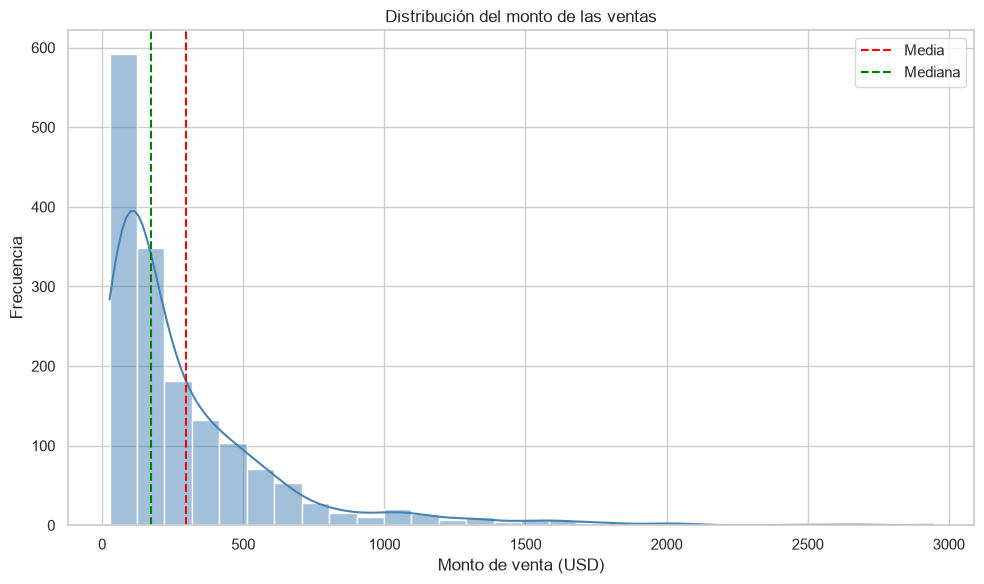

In [94]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=ventas,
    x="Monto_Total_USD",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.axvline(
    ventas["Monto_Total_USD"].mean(),
    color="red",
    linestyle="--",
    label="Media"
)

plt.axvline(
    ventas["Monto_Total_USD"].median(),
    color="green",
    linestyle="--",
    label="Mediana"
)

plt.title("Distribución del monto de las ventas")
plt.xlabel("Monto de venta (USD)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()

plt.savefig(
    GRAFICOS / "01_histograma_monto.png",
    dpi=150
)

plt.show()

### 6.2. Diagrama de caja del monto de venta

El boxplot permite visualizar la mediana, los cuartiles,
la dispersión y los posibles valores atípicos.

Se utiliza la regla de Tukey, basada en 1.5 veces
el rango intercuartílico (IQR).

Los valores atípicos se analizan sin eliminarlos
automáticamente, ya que pueden representar operaciones
comerciales válidas.

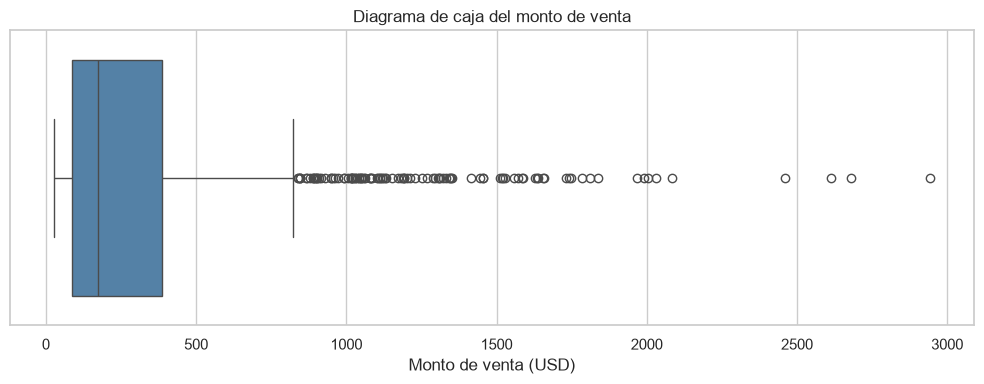

In [95]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=ventas,
    x="Monto_Total_USD",
    color="steelblue"
)

plt.title("Diagrama de caja del monto de venta")
plt.xlabel("Monto de venta (USD)")
plt.tight_layout()

plt.savefig(
    GRAFICOS / "02_boxplot_monto.png",
    dpi=150
)

plt.show()

### 6.3. Identificación de valores atípicos mediante IQR

Se calculan los límites inferior y superior mediante
la regla de Tukey:

- Límite inferior: Q1 - 1.5 * IQR.
- Límite superior: Q3 + 1.5 * IQR.

Las observaciones que se encuentran fuera de estos
límites se consideran posibles valores atípicos.

In [96]:
q1_monto = ventas["Monto_Total_USD"].quantile(0.25)
q3_monto = ventas["Monto_Total_USD"].quantile(0.75)

iqr_monto = q3_monto - q1_monto

limite_inferior = q1_monto - 1.5 * iqr_monto
limite_superior = q3_monto + 1.5 * iqr_monto

outliers_monto = ventas[
    (ventas["Monto_Total_USD"] < limite_inferior) |
    (ventas["Monto_Total_USD"] > limite_superior)
]

print("Q1:", round(q1_monto, 2))
print("Q3:", round(q3_monto, 2))
print("IQR:", round(iqr_monto, 2))

print("Límite inferior:", round(limite_inferior, 2))
print("Límite superior:", round(limite_superior, 2))

print("Cantidad de outliers:", len(outliers_monto))

print(
    "Porcentaje de outliers:",
    round(len(outliers_monto) / len(ventas) * 100, 2),
    "%"
)

Q1: 86.14
Q3: 385.49
IQR: 299.35
Límite inferior: -362.89
Límite superior: 834.52
Cantidad de outliers: 107
Porcentaje de outliers: 6.62 %


In [97]:
outliers_monto[[
    "ID_Transaccion",
    "Categoria",
    "Producto",
    "Precio_Unitario",
    "Cantidad",
    "Monto_Total_USD"
]].sort_values(
    "Monto_Total_USD",
    ascending=False
).head(10)

,ID_Transaccion,Categoria,Producto,Precio_Unitario,Cantidad,Monto_Total_USD
211,TX-G1-10211,Electrónica,"Tablet 10""",654.06,5,2943.27
550,TX-G1-10550,Electrónica,Auriculares Bluetooth,670.18,5,2680.72
806,TX-G1-10806,Electrónica,Teclado Mecánico,550.47,5,2614.73
1660,TX-G1-11660,Electrónica,"Smart TV 55""",615.42,4,2461.68
784,TX-G1-10784,Electrónica,Teclado Mecánico,438.77,5,2084.16
534,TX-G1-10534,Electrónica,Smartphone Pro,507.47,4,2029.88
1982,TX-G1-11982,Electrónica,Auriculares Bluetooth,471.93,5,2005.70
1020,TX-G1-11020,Electrónica,Smartphone Pro,663.34,3,1990.02
1607,TX-G1-11607,Electrónica,"Smart TV 55""",656.18,3,1968.54
1748,TX-G1-11748,Electrónica,Teclado Mecánico,645.00,3,1838.25


### 6.4. Distribución de los montos por categoría

Se utilizan diagramas de caja segmentados por categoría
para comparar las medianas, los rangos intercuartílicos,
la dispersión y los valores atípicos de cada grupo.

Esto permite identificar diferencias en el
comportamiento comercial de las categorías.

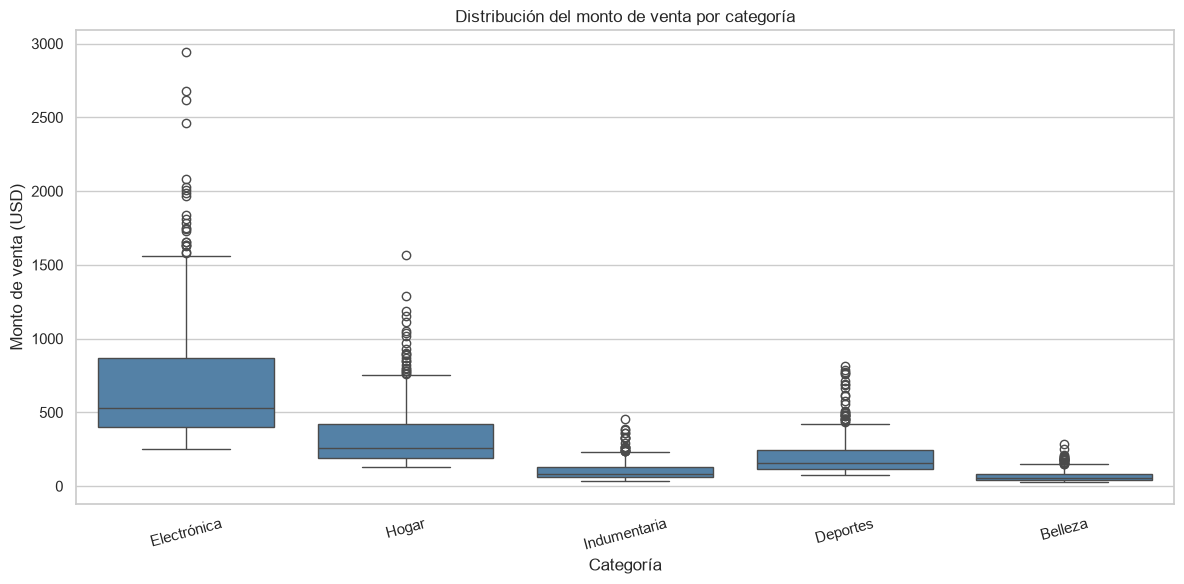

In [98]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=ventas,
    x="Categoria",
    y="Monto_Total_USD",
    color="steelblue"
)

plt.title("Distribución del monto de venta por categoría")
plt.xlabel("Categoría")
plt.ylabel("Monto de venta (USD)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    GRAFICOS / "03_boxplot_categoria.png",
    dpi=150
)

plt.show()

## 7. Análisis del rendimiento comercial

Se analiza el comportamiento comercial de Click&Buy Latam
mediante la agrupación de las ventas positivas entregadas.

### 7.1. Rendimiento por categoría

Se compara la cantidad de transacciones, el monto total
de las ventas, el ticket promedio, la mediana y la
participación porcentual de cada categoría.

In [99]:
rendimiento_categoria = ventas.groupby("Categoria").agg(
    Transacciones=("ID_Transaccion", "count"),
    Unidades_Vendidas=("Cantidad", "sum"),
    Ingresos_USD=("Monto_Total_USD", "sum"),
    Ticket_Promedio=("Monto_Total_USD", "mean"),
    Mediana=("Monto_Total_USD", "median")
)

# Participación de cada categoría sobre el total
rendimiento_categoria["Participacion_Pct"] = (
    rendimiento_categoria["Ingresos_USD"] /
    rendimiento_categoria["Ingresos_USD"].sum()
) * 100

# Ordenar de mayor a menor ingreso
rendimiento_categoria = rendimiento_categoria.sort_values(
    "Ingresos_USD",
    ascending=False
)

rendimiento_categoria.round(2)

,Transacciones,Unidades_Vendidas,Ingresos_USD,Ticket_Promedio,Mediana,Participacion_Pct
Categoria,,,,,,
Electrónica,348,546,244723.44,703.23,532.74,51.11
Hogar,323,514,110662.00,342.61,260.15,23.11
Deportes,337,540,69977.56,207.65,154.06,14.61
Indumentaria,309,501,32863.39,106.35,81.62,6.86
Belleza,300,456,20591.13,68.64,52.86,4.30


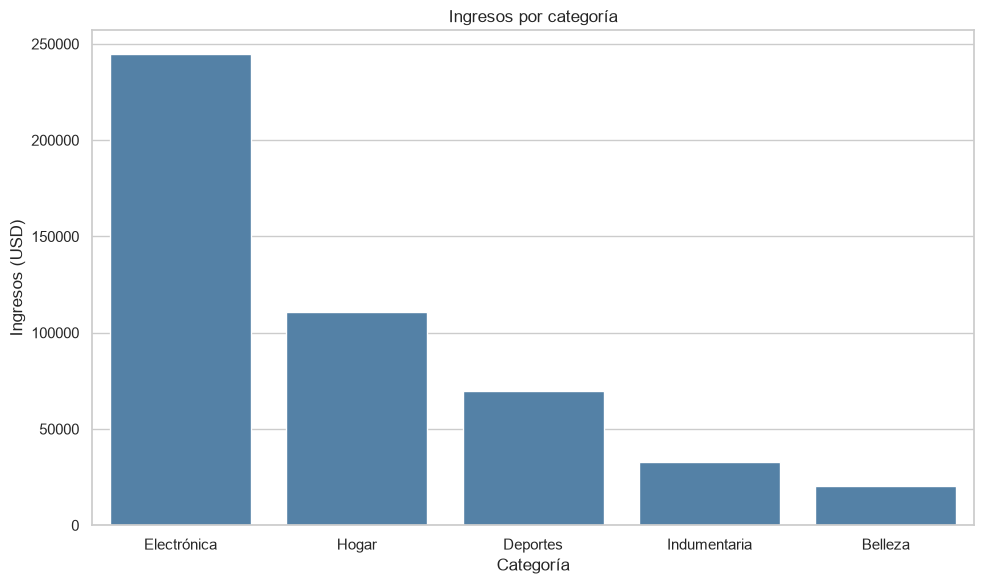

In [100]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rendimiento_categoria.reset_index(),
    x="Categoria",
    y="Ingresos_USD",
    color="steelblue"
)

plt.title("Ingresos por categoría")
plt.xlabel("Categoría")
plt.ylabel("Ingresos (USD)")
plt.tight_layout()

plt.savefig(
    GRAFICOS / "04_ingresos_categoria.png",
    dpi=150
)

plt.show()

### 7.2. Ticket promedio por canal de venta

Se analiza el comportamiento de las ventas según
el canal utilizado por los clientes.

Se comparan las transacciones, los ingresos,
la media, la mediana y la desviación estándar
de los importes por canal.

In [101]:
rendimiento_canal = ventas.groupby("Canal_Venta").agg(
    Transacciones=("ID_Transaccion", "count"),
    Ingresos_USD=("Monto_Total_USD", "sum"),
    Ticket_Promedio=("Monto_Total_USD", "mean"),
    Mediana=("Monto_Total_USD", "median"),
    Desviacion_Estandar=("Monto_Total_USD", "std")
)

rendimiento_canal = rendimiento_canal.sort_values(
    "Ticket_Promedio",
    ascending=False
)

rendimiento_canal.round(2)

,Transacciones,Ingresos_USD,Ticket_Promedio,Mediana,Desviacion_Estandar
Canal_Venta,,,,,
Marketplace,539,162411.01,301.32,172.16,360.49
Sitio Web,527,158364.30,300.50,179.23,335.82
App Mobile,551,158042.21,286.83,171.66,311.89


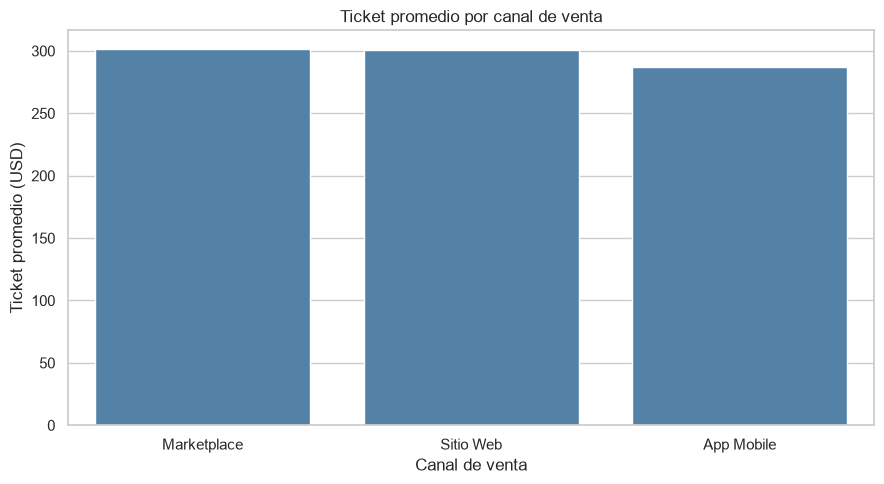

In [102]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=rendimiento_canal.reset_index(),
    x="Canal_Venta",
    y="Ticket_Promedio",
    color="steelblue"
)

plt.title("Ticket promedio por canal de venta")
plt.xlabel("Canal de venta")
plt.ylabel("Ticket promedio (USD)")
plt.tight_layout()

plt.savefig(
    GRAFICOS / "05_ticket_canal.png",
    dpi=150
)

plt.show()

### 7.3. Ticket promedio por método de pago

Se analiza la relación entre los métodos de pago
y los importes de las ventas.

El objetivo es identificar diferencias en el
comportamiento comercial según la forma de pago
seleccionada por los clientes.

In [103]:
rendimiento_pago = ventas.groupby("Metodo_Pago").agg(
    Transacciones=("ID_Transaccion", "count"),
    Ingresos_USD=("Monto_Total_USD", "sum"),
    Ticket_Promedio=("Monto_Total_USD", "mean"),
    Mediana=("Monto_Total_USD", "median"),
    Desviacion_Estandar=("Monto_Total_USD", "std")
)

rendimiento_pago = rendimiento_pago.sort_values(
    "Ticket_Promedio",
    ascending=False
)

rendimiento_pago.round(2)

,Transacciones,Ingresos_USD,Ticket_Promedio,Mediana,Desviacion_Estandar
Metodo_Pago,,,,,
Transferencia,448,145147.70,323.99,176.20,402.98
Tarjeta Crédito,367,107100.74,291.83,174.34,322.60
MercadoPago,415,117656.29,283.51,174.75,307.91
Tarjeta Débito,387,108912.79,281.43,169.16,289.60


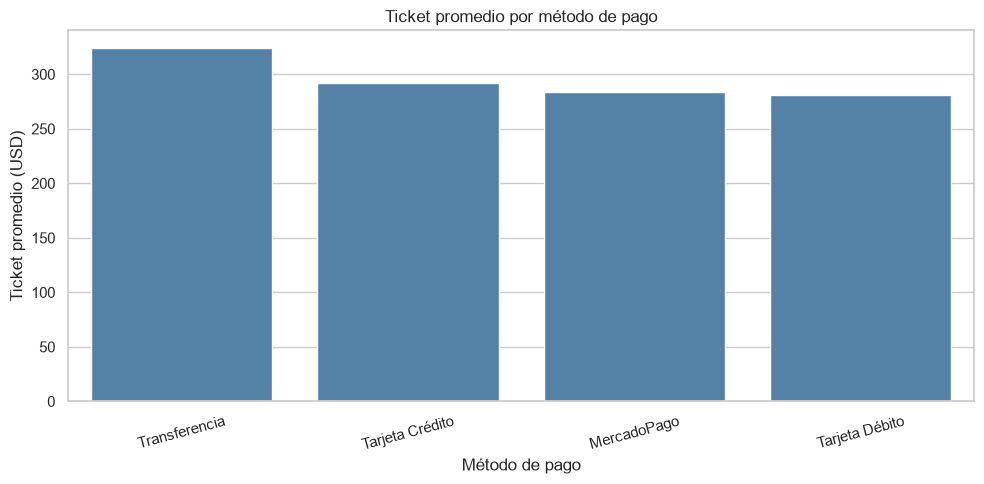

In [104]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=rendimiento_pago.reset_index(),
    x="Metodo_Pago",
    y="Ticket_Promedio",
    color="steelblue"
)

plt.title("Ticket promedio por método de pago")
plt.xlabel("Método de pago")
plt.ylabel("Ticket promedio (USD)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    GRAFICOS / "06_ticket_metodo_pago.png",
    dpi=150
)

plt.show()

### 7.4. Análisis combinado de canal y método de pago

Se realiza una comparación cruzada entre los canales
de venta y los métodos de pago.

Mediante una tabla dinámica se identifica el ticket
promedio correspondiente a cada combinación.

In [105]:
ticket_combinado = pd.pivot_table(
    ventas,
    values="Monto_Total_USD",
    index="Canal_Venta",
    columns="Metodo_Pago",
    aggfunc="mean"
)

ticket_combinado.round(2)

Metodo_Pago,MercadoPago,Tarjeta Crédito,Tarjeta Débito,Transferencia
Canal_Venta,,,,
App Mobile,294.33,288.06,296.55,270.95
Marketplace,272.20,294.32,283.69,351.75
Sitio Web,285.50,293.34,261.20,352.90


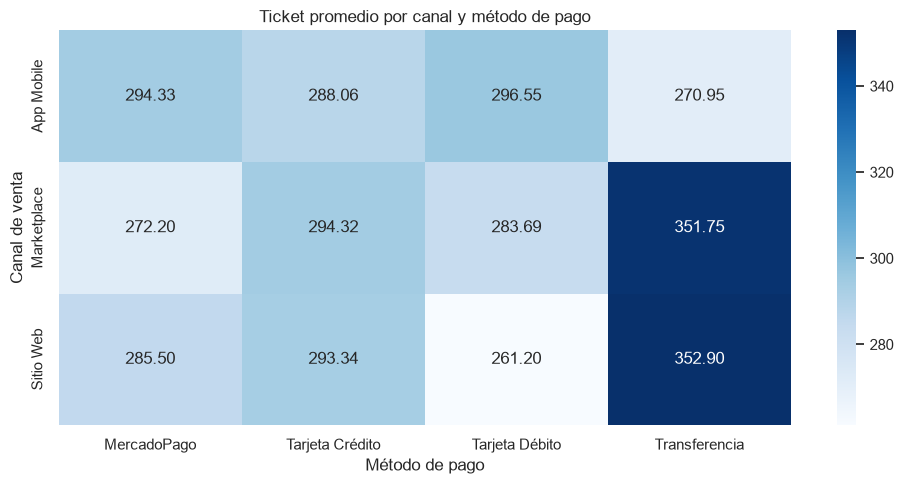

In [106]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    ticket_combinado,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.title("Ticket promedio por canal y método de pago")
plt.xlabel("Método de pago")
plt.ylabel("Canal de venta")
plt.tight_layout()

plt.savefig(
    GRAFICOS / "07_heatmap_ticket_combinado.png",
    dpi=150
)

plt.show()

In [107]:
cantidad_combinada = pd.pivot_table(
    ventas,
    values="ID_Transaccion",
    index="Canal_Venta",
    columns="Metodo_Pago",
    aggfunc="count"
)

cantidad_combinada

Metodo_Pago,MercadoPago,Tarjeta Crédito,Tarjeta Débito,Transferencia
Canal_Venta,,,,
App Mobile,128,127,140,156
Marketplace,147,118,128,146
Sitio Web,140,122,119,146


## 8. Análisis de cancelaciones y devoluciones

Se analiza el impacto comercial de los pedidos
cancelados y devueltos, identificando las categorías
que presentan mayor cantidad de estas operaciones.

Los importes asociados a estos pedidos no se
consideran ingresos efectivos.

Se utiliza el dataset completo para conocer la
proporción de operaciones canceladas y devueltas.

In [108]:
total_transacciones = len(df)

tasa_cancelacion = len(cancelados) / total_transacciones * 100
tasa_devolucion = len(devueltos) / total_transacciones * 100

print("Total de transacciones:", total_transacciones)
print("Pedidos cancelados:", len(cancelados))
print("Pedidos devueltos:", len(devueltos))

print("Tasa de cancelación:", round(tasa_cancelacion, 2), "%")
print("Tasa de devolución:", round(tasa_devolucion, 2), "%")

print(
    "Tasa combinada:",
    round(tasa_cancelacion + tasa_devolucion, 2),
    "%"
)

Total de transacciones: 2000
Pedidos cancelados: 92
Pedidos devueltos: 84
Tasa de cancelación: 4.6 %
Tasa de devolución: 4.2 %
Tasa combinada: 8.8 %


### 8.1. Cancelaciones y devoluciones por categoría

Se comparan los estados de pedido según la categoría
comercial.

Además de las cantidades absolutas, se calculan
las tasas de cancelación y devolución para evitar
comparaciones incorrectas entre categorías con
diferentes volúmenes de transacciones.

In [109]:
estados_categoria = pd.crosstab(
    df["Categoria"],
    df["Estado_Pedido"]
)

estados_categoria

Estado_Pedido,Cancelado,Devuelto,En Tránsito,Entregado
Categoria,,,,
Belleza,9,23,42,303
Deportes,18,10,39,340
Electrónica,14,16,35,355
Hogar,24,23,36,328
Indumentaria,27,12,32,314


In [110]:
tasas_categoria = pd.DataFrame({
    "Total_Pedidos": estados_categoria.sum(axis=1),
    "Cancelados": estados_categoria["Cancelado"],
    "Devueltos": estados_categoria["Devuelto"]
})

tasas_categoria["Tasa_Cancelacion_Pct"] = (
    tasas_categoria["Cancelados"] /
    tasas_categoria["Total_Pedidos"]
) * 100

tasas_categoria["Tasa_Devolucion_Pct"] = (
    tasas_categoria["Devueltos"] /
    tasas_categoria["Total_Pedidos"]
) * 100

tasas_categoria["Tasa_Combinada_Pct"] = (
    tasas_categoria["Tasa_Cancelacion_Pct"] +
    tasas_categoria["Tasa_Devolucion_Pct"]
)

tasas_categoria.round(2)

,Total_Pedidos,Cancelados,Devueltos,Tasa_Cancelacion_Pct,Tasa_Devolucion_Pct,Tasa_Combinada_Pct
Categoria,,,,,,
Belleza,377,9,23,2.39,6.10,8.49
Deportes,407,18,10,4.42,2.46,6.88
Electrónica,420,14,16,3.33,3.81,7.14
Hogar,411,24,23,5.84,5.60,11.44
Indumentaria,385,27,12,7.01,3.12,10.13


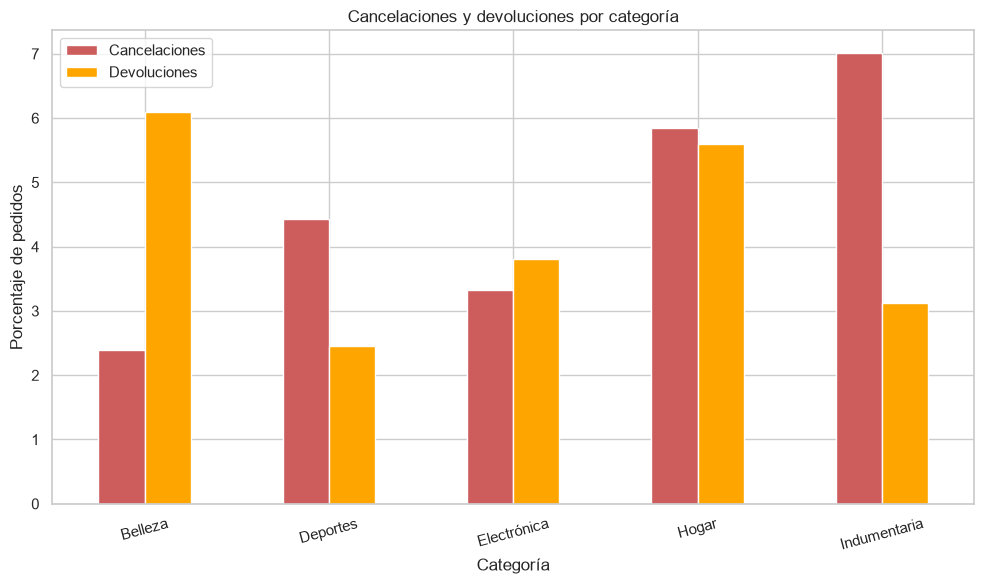

In [111]:
tasas_categoria[[
    "Tasa_Cancelacion_Pct",
    "Tasa_Devolucion_Pct"
]].plot(
    kind="bar",
    figsize=(10, 6),
    color=["indianred", "orange"]
)

plt.title("Cancelaciones y devoluciones por categoría")
plt.xlabel("Categoría")
plt.ylabel("Porcentaje de pedidos")
plt.xticks(rotation=15)
plt.legend(["Cancelaciones", "Devoluciones"])
plt.tight_layout()

plt.savefig(
    GRAFICOS / "08_cancelaciones_devoluciones.png",
    dpi=150
)

plt.show()

### 8.2. Impacto monetario de las operaciones

Se cuantifican los importes asociados a los pedidos
cancelados, devueltos y en tránsito.

Se consideran por separado los importes positivos
y negativos para evitar que se compensen entre sí
y oculten el volumen monetario de las operaciones.

Estos valores representan importes registrados,
no pérdidas contables ni reembolsos confirmados.

Los pedidos cancelados presentan importes positivos
por USD 25.012,55 e importes negativos por USD 579,00.

Los pedidos devueltos presentan importes positivos
por USD 23.147,63 e importes negativos por USD 99,64.

Los pedidos en tránsito representan un monto
registrado de USD 48.025,82.

Estas cifras permiten dimensionar el volumen
monetario de las operaciones no concretadas,
pero no constituyen pérdidas económicas confirmadas.

In [112]:
impacto_economico = pd.DataFrame({
    "Estado": [
        "Cancelado",
        "Devuelto",
        "En Tránsito"
    ],
    "Transacciones": [
        len(cancelados),
        len(devueltos),
        len(en_transito)
    ],
    "Monto_Positive_USD": [
        cancelados.loc[
            cancelados["Monto_Total_USD"] > 0,
            "Monto_Total_USD"
        ].sum(),
        devueltos.loc[
            devueltos["Monto_Total_USD"] > 0,
            "Monto_Total_USD"
        ].sum(),
        en_transito.loc[
            en_transito["Monto_Total_USD"] > 0,
            "Monto_Total_USD"
        ].sum()
    ],
    "Monto_Negativo_USD": [
        cancelados.loc[
            cancelados["Monto_Total_USD"] < 0,
            "Monto_Total_USD"
        ].sum(),
        devueltos.loc[
            devueltos["Monto_Total_USD"] < 0,
            "Monto_Total_USD"
        ].sum(),
        en_transito.loc[
            en_transito["Monto_Total_USD"] < 0,
            "Monto_Total_USD"
        ].sum()
    ]
})

impacto_economico = impacto_economico.rename(
    columns={"Monto_Positive_USD": "Monto_Positivo_USD"}
)

impacto_economico.round(2)

,Estado,Transacciones,Monto_Positivo_USD,Monto_Negativo_USD
0,Cancelado,92,25012.55,-579.00
1,Devuelto,84,23147.63,-99.64
2,En Tránsito,184,48025.82,0.00


## 9. Análisis de descuentos

Se estudia la relación entre los porcentajes de
descuento y el comportamiento de las ventas.

Se comparan la cantidad de transacciones, las
unidades vendidas, los ingresos y el ticket promedio
para cada nivel de descuento.

In [113]:
analisis_descuentos = ventas.groupby("Descuento_Pct").agg(
    Transacciones=("ID_Transaccion", "count"),
    Unidades_Vendidas=("Cantidad", "sum"),
    Ingresos_USD=("Monto_Total_USD", "sum"),
    Ticket_Promedio=("Monto_Total_USD", "mean"),
    Mediana=("Monto_Total_USD", "median")
)

analisis_descuentos.round(2)

,Transacciones,Unidades_Vendidas,Ingresos_USD,Ticket_Promedio,Mediana
Descuento_Pct,,,,,
0.00,408,619,133141.78,326.33,184.91
0.05,302,478,92916.46,307.67,177.32
0.10,287,450,88848.40,309.58,190.15
0.15,312,509,85083.17,272.70,169.28
0.20,308,501,78827.71,255.93,141.62


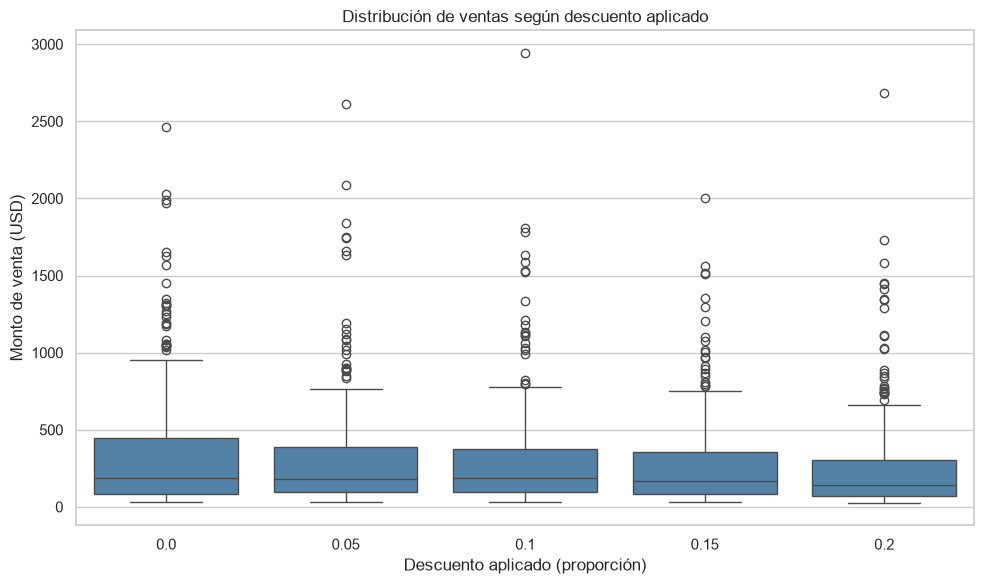

In [114]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=ventas,
    x="Descuento_Pct",
    y="Monto_Total_USD",
    color="steelblue"
)

plt.title("Distribución de ventas según descuento aplicado")
plt.xlabel("Descuento aplicado (proporción)")
plt.ylabel("Monto de venta (USD)")
plt.tight_layout()

plt.savefig(
    GRAFICOS / "09_boxplot_descuentos.png",
    dpi=150
)

plt.show()

## 10. Análisis bivariado y diagnóstico

El análisis bivariado estudia la relación entre
dos variables.

Se utilizan gráficos de dispersión y el coeficiente
de correlación de Pearson para identificar
asociaciones lineales entre variables cuantitativas.

Una correlación estadística no implica causalidad,
por lo que las relaciones identificadas deben
interpretarse considerando el contexto comercial.

### 10.1. Relación entre precio unitario y monto total

Se analiza la relación entre el precio unitario
del producto y el importe final de la transacción
mediante un gráfico de dispersión.

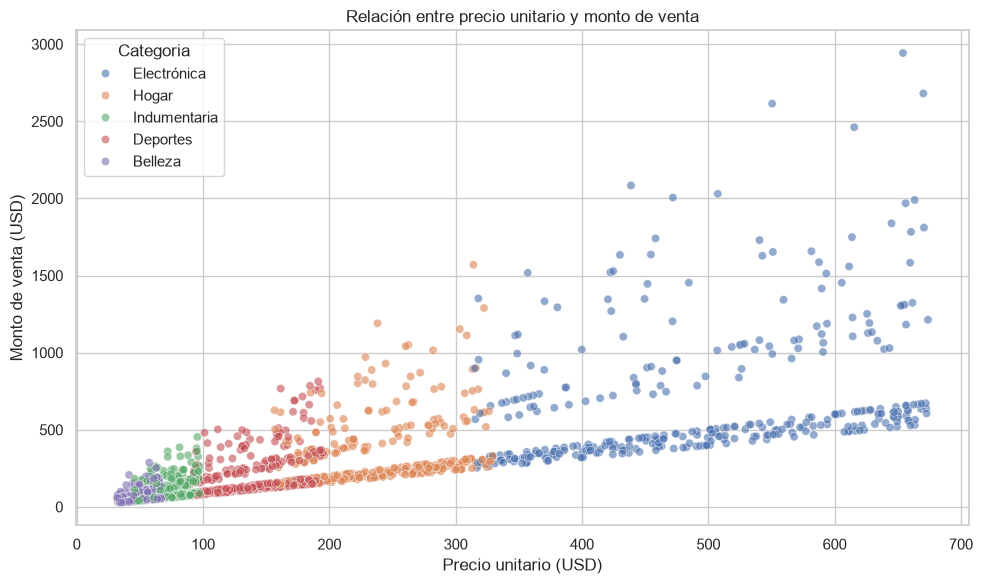

In [115]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=ventas,
    x="Precio_Unitario",
    y="Monto_Total_USD",
    hue="Categoria",
    alpha=0.6
)

plt.title("Relación entre precio unitario y monto de venta")
plt.xlabel("Precio unitario (USD)")
plt.ylabel("Monto de venta (USD)")
plt.tight_layout()

plt.savefig(
    GRAFICOS / "10_scatter_precio_monto.png",
    dpi=150
)

plt.show()

### 10.2. Relación entre descuento y monto total

Se analiza la asociación entre el porcentaje de
descuento aplicado y el importe de las ventas.

La visualización permite explorar patrones sin
establecer una relación causal directa.

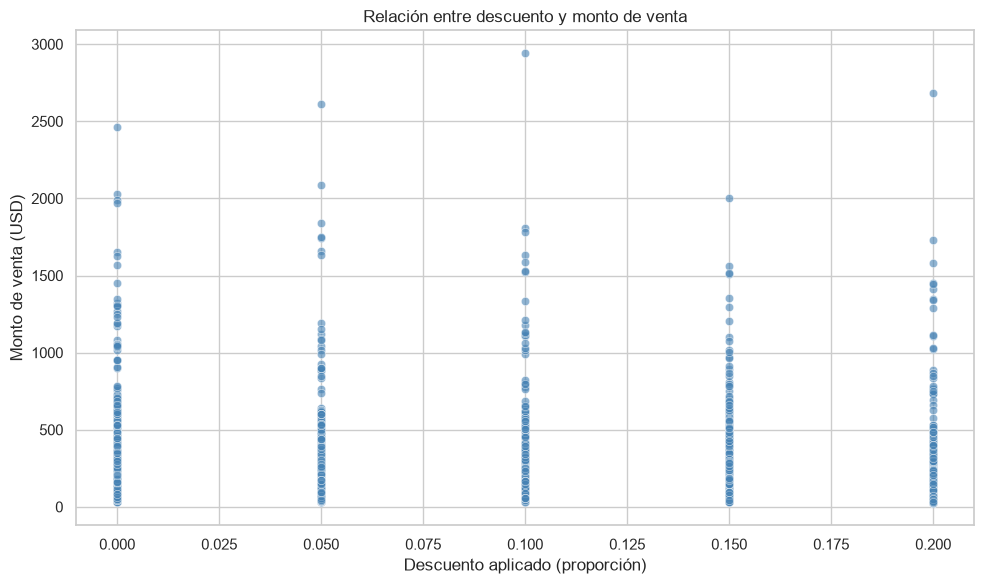

In [116]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=ventas,
    x="Descuento_Pct",
    y="Monto_Total_USD",
    alpha=0.6,
    color="steelblue"
)

plt.title("Relación entre descuento y monto de venta")
plt.xlabel("Descuento aplicado (proporción)")
plt.ylabel("Monto de venta (USD)")
plt.tight_layout()

plt.savefig(
    GRAFICOS / "11_scatter_descuento_monto.png",
    dpi=150
)

plt.show()

### 10.3. Matriz de correlación de Pearson

El coeficiente de correlación de Pearson (r)
mide la fuerza y dirección de la asociación
lineal entre dos variables cuantitativas.

Sus valores se encuentran entre -1 y +1:

- Valores positivos: asociación lineal directa.
- Valores negativos: asociación lineal inversa.
- Valores cercanos a cero: asociación lineal débil
  o inexistente.

La correlación no implica causalidad.

In [117]:
correlacion = ventas[variables_numericas].corr(
    method="pearson"
)

correlacion.round(3)

,Precio_Unitario,Cantidad,Descuento_Pct,Monto_Total_USD
Precio_Unitario,1.000,-0.004,-0.042,0.732
Cantidad,-0.004,1.000,0.043,0.524
Descuento_Pct,-0.042,0.043,1.000,-0.076
Monto_Total_USD,0.732,0.524,-0.076,1.000


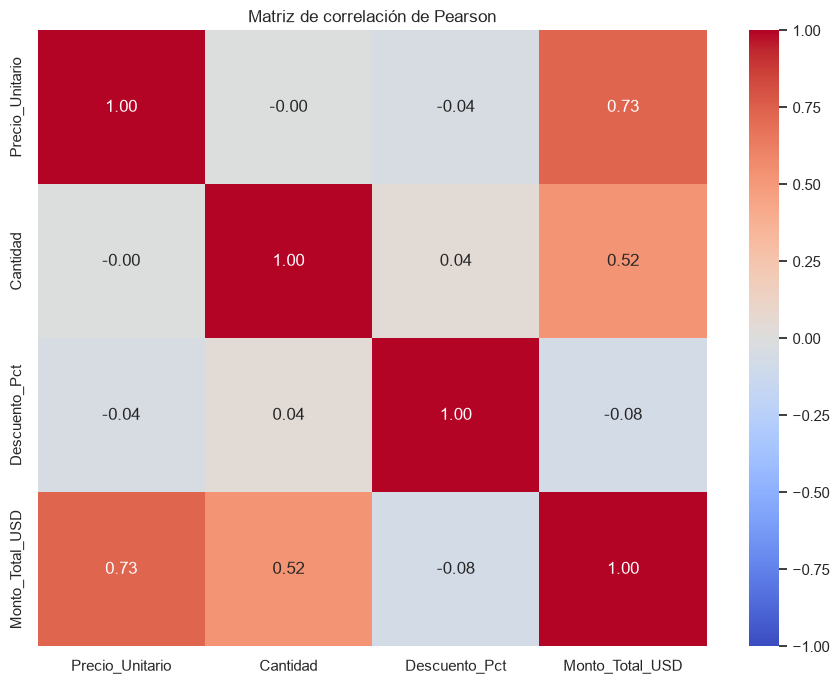

In [118]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Matriz de correlación de Pearson")
plt.tight_layout()

plt.savefig(
    GRAFICOS / "12_heatmap_pearson.png",
    dpi=150
)

plt.show()

## 11. Interpretación de los resultados

Se integran los resultados del análisis descriptivo,
exploratorio y diagnóstico para identificar patrones
y formular hipótesis comerciales.

### 11.1. Resumen estadístico integrado

Se consolidan las medidas de tendencia central,
dispersión y forma de distribución.

In [119]:
resumen_estadistico = pd.concat(
    [
        tendencia_central,
        dispersion,
        forma_distribucion
    ],
    axis=1
)

resumen_estadistico.round(3)

,Media,Mediana,Moda,Minimo,Maximo,Rango,Varianza,Desviacion_Estandar,Q1,Q3,IQR,Asimetria,Curtosis
Precio_Unitario,206.974,154.23,55.87,31.85,673.85,642.00,30093.818,173.476,66.07,296.89,230.82,1.152,0.281
Cantidad,1.581,1.00,1.00,1.00,5.00,4.00,0.885,0.941,1.00,2.00,1.00,1.766,2.645
Descuento_Pct,0.094,0.10,0.00,0.00,0.20,0.20,0.005,0.073,0.00,0.15,0.15,0.085,-1.378
Monto_Total_USD,296.115,174.93,80.92,26.34,2943.27,2916.93,113122.742,336.337,86.14,385.49,299.35,2.795,10.866


### 11.2. Interpretación estadística del monto de venta

El análisis se realizó sobre 1.617 transacciones
entregadas con cantidades e importes positivos.

La media del monto de venta es de USD 296,11,
mientras que la mediana es de USD 174,93.

La diferencia entre ambas medidas y el coeficiente
de asimetría positivo de 2,795 indican una
distribución sesgada hacia la derecha.

El 50% central de las ventas se encuentra entre
USD 86,14 y USD 385,49, con un rango intercuartílico
de USD 299,35.

La desviación estándar de USD 336,34 indica una
considerable variabilidad en los importes.

Mediante la regla de Tukey se identificaron 107
valores atípicos, los cuales se conservaron porque
pueden representar operaciones comerciales válidas.

En este contexto, la mediana resulta más representativa
del importe habitual de una venta que la media,
debido a la influencia de los valores elevados.

### 11.3. Interpretación del rendimiento comercial

Electrónica es la categoría con mayor monto de ventas,
alcanzando USD 244.723,44 y representando aproximadamente
el 51,11% del total de las ventas analizadas.

También presenta el mayor ticket promedio, con
USD 703,23 por transacción.

Marketplace presenta el mayor ticket promedio entre
los canales de venta, con USD 301,32, seguido por
Sitio Web con USD 300,50 y App Mobile con USD 286,83.

Las diferencias entre los canales son relativamente
reducidas, especialmente entre Marketplace y Sitio Web.

En cuanto a los métodos de pago, Transferencia
presenta el mayor ticket promedio, con USD 323,99,
mientras que Tarjeta Débito presenta el menor,
con USD 281,43.

Estas diferencias describen asociaciones observadas,
pero no permiten afirmar que un canal o método de pago
provoque directamente un aumento en el importe de compra.

### 11.4. Interpretación de la correlación de Pearson

La relación entre el precio unitario y el monto
total presenta una correlación positiva de 0,732,
indicando una asociación lineal fuerte.

La cantidad y el monto total presentan una
correlación positiva moderada de 0,524.

Por otra parte, el descuento y el monto total
presentan una correlación negativa muy débil
de -0,076.

Las demás relaciones presentan coeficientes
cercanos a cero, indicando escasa asociación lineal.

Los resultados deben interpretarse considerando
que el monto total se calcula mediante la fórmula:

Monto = Precio x Cantidad x (1 - Descuento)

Por lo tanto, parte de las asociaciones observadas
se explica por la propia construcción matemática
de la variable.

La correlación no implica causalidad y no permite
afirmar que modificar una variable produzca
necesariamente un determinado comportamiento
comercial en los clientes.

## 12. Formulación de hipótesis

### Hipótesis 1: Categoría comercial

Los productos de Electrónica podrían generar mayores
ingresos debido a sus precios unitarios elevados.

El análisis muestra que esta categoría concentra
la mayor participación monetaria y presenta el
mayor ticket promedio.

### Hipótesis 2: Método de pago

Los clientes que realizan compras de importes
elevados podrían preferir la transferencia bancaria.

Este método presenta el mayor ticket promedio.
Sin embargo, la categoría del producto y otras
variables podrían explicar parte de esta diferencia.

### Hipótesis 3: Canal de venta

Las diferencias en el ticket promedio entre los
canales podrían estar relacionadas con la composición
de los productos comercializados en cada uno.

Los resultados no permiten afirmar que el canal
sea la causa directa de las diferencias observadas.

### Hipótesis 4: Cancelaciones y devoluciones

Las diferencias entre las tasas de cancelación y
devolución por categoría podrían estar relacionadas
con características de los productos, problemas
logísticos o expectativas de los clientes.

El dataset no contiene los motivos específicos
de estas operaciones, por lo que la hipótesis
requiere información adicional para ser validada.

### Alcance del diagnóstico

Las hipótesis planteadas representan posibles
explicaciones de los patrones identificados.

No constituyen relaciones causales demostradas.

## 13. Hallazgos analíticos

### Hallazgo 1: Concentración comercial en Electrónica

Electrónica representa aproximadamente el 51,11%
del monto total de las ventas positivas entregadas,
con USD 244.723,44.

Esta concentración indica una elevada dependencia
comercial de una sola categoría.

Se recomienda monitorear su rendimiento y evaluar
oportunidades de crecimiento en otras categorías.

### Hallazgo 2: Asimetría en los importes de venta

El ticket promedio es de USD 296,11, mientras que
la mediana es de USD 174,93.

La asimetría positiva indica que las operaciones
de importes elevados influyen sobre el promedio.

Se recomienda utilizar conjuntamente la media
y la mediana como indicadores comerciales.

### Hallazgo 3: Diferencias según canal y método de pago

Marketplace presenta el mayor ticket promedio
entre los canales, con USD 301,32.

Transferencia presenta el mayor ticket promedio
entre los métodos de pago, con USD 323,99.

Se recomienda profundizar el análisis segmentando
por categoría antes de adoptar decisiones comerciales
basadas exclusivamente en estas diferencias.

### Hallazgo 4: Cancelaciones y devoluciones

El 8,8% de las transacciones corresponde a pedidos
cancelados o devueltos.

Hogar presenta la mayor tasa combinada de ambas
operaciones, con aproximadamente 11,44%.

Se recomienda investigar los motivos de estas
operaciones para identificar oportunidades de mejora.

### Hallazgo 5: Registros negativos y control comercial

Se identificaron 26 registros con cantidades negativas,
de los cuales 23 figuran como entregados.

Estos 23 registros representan un importe acumulado
de -USD 5.056,19.

Se recomienda revisar su significado comercial
antes de incorporarlos al cálculo definitivo
de ingresos netos.

Los registros negativos no deben clasificarse
automáticamente como devoluciones.

## 14. Conclusión general

El análisis descriptivo, exploratorio y diagnóstico
permitió comprender el comportamiento comercial
de Click&Buy Latam a partir del dataset preparado
por Ingeniería Analítica.

Se aplicaron medidas de tendencia central,
dispersión, asimetría, visualizaciones estadísticas
y correlación de Pearson, siguiendo los contenidos
de la Unidad 4.

Los resultados permitieron identificar patrones
comerciales, diferencias entre categorías, canales
y métodos de pago, así como oportunidades de mejora
relacionadas con cancelaciones y devoluciones.

El análisis distingue las asociaciones estadísticas
de las relaciones causales y reconoce las
limitaciones de la información disponible.

Los resultados obtenidos serán utilizados como
base para la construcción del tablero interactivo
y la propuesta estratégica de negocio.

## 15. Exportación de resultados

Se exportan las principales tablas estadísticas
y comerciales para facilitar su consulta y
reutilización por el equipo de Business Intelligence.

Los archivos se almacenan dentro de la carpeta
docs/analisis_de_datos sin modificar el dataset limpio.

In [120]:
DOCS_ANALISIS = BASE / "docs" / "analisis_de_datos"

DOCS_ANALISIS.mkdir(
    parents=True,
    exist_ok=True
)

resumen_estadistico.to_csv(
    DOCS_ANALISIS / "resumen_estadistico.csv",
    encoding="utf-8-sig"
)

rendimiento_categoria.to_csv(
    DOCS_ANALISIS / "rendimiento_categoria.csv",
    encoding="utf-8-sig"
)

rendimiento_canal.to_csv(
    DOCS_ANALISIS / "rendimiento_canal.csv",
    encoding="utf-8-sig"
)

rendimiento_pago.to_csv(
    DOCS_ANALISIS / "rendimiento_metodo_pago.csv",
    encoding="utf-8-sig"
)

tasas_categoria.to_csv(
    DOCS_ANALISIS / "tasas_cancelacion_devolucion.csv",
    encoding="utf-8-sig"
)

impacto_economico.to_csv(
    DOCS_ANALISIS / "impacto_economico.csv",
    index=False,
    encoding="utf-8-sig"
)

correlacion.to_csv(
    DOCS_ANALISIS / "correlacion_pearson.csv",
    encoding="utf-8-sig"
)

ticket_combinado.to_csv(
    DOCS_ANALISIS / "ticket_canal_metodo_pago.csv",
    encoding="utf-8-sig"
)

print("Resultados exportados correctamente.")
print("Análisis exploratorio finalizado.")

Resultados exportados correctamente.
Análisis exploratorio finalizado.


In [121]:
print("Transacciones totales:", len(df))
print("Columnas:", df.shape[1])
print("Nulos:", df.isna().sum().sum())
print("IDs duplicados:", df["ID_Transaccion"].duplicated().sum())

print("Ventas positivas:", len(ventas))
print("Monto total:", round(ventas["Monto_Total_USD"].sum(), 2))
print("Ticket promedio:", round(ventas["Monto_Total_USD"].mean(), 2))
print("Mediana:", round(ventas["Monto_Total_USD"].median(), 2))

print("\nEstados de pedidos:")
print(df["Estado_Pedido"].value_counts())

Transacciones totales: 2000
Columnas: 23
Nulos: 0
IDs duplicados: 0
Ventas positivas: 1617
Monto total: 478817.52
Ticket promedio: 296.11
Mediana: 174.93

Estados de pedidos:
Estado_Pedido
Entregado      1640
En Tránsito     184
Cancelado        92
Devuelto         84
Name: count, dtype: int64
